# Discussion 08 · From pet photos to predictions

[Discussion Slide](https://docs.google.com/presentation/d/1ahSLFtxtjW0pXnJl2EoShCY0UzVn39dK27guZAXlBPs/edit?usp=sharing)

[Kaggle dataset](https://www.kaggle.com/competitions/petfinder-pawpularity-score/data)

[HuggingFace](https://huggingface.co/)

In [1]:
# common utilities
import numpy as np
import pandas as pd
from PIL import Image
from zipfile import ZipFile
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

# deep learning libararies, currently missing in dsc80 env
# %pip install torch transformers h5py
# Because PyTorch and transformers might reinstall some packages like numpy etc. 
# It is recommended to create another environment for this demo. 
import h5py
import torch
from transformers import AutoImageProcessor, ViTModel

SEED = 42

In [2]:
# basic processing modules/functions
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# experiment related modules/functions
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split, KFold, GridSearchCV

# supported models
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression

## 1. Prepare Data

In [3]:
# Read the CSVs directly from the ZIP.
photos = ZipFile("petfinder-pawpularity-score.zip")
labeled = pd.read_csv(photos.open("train.csv"))
kaggle_test = pd.read_csv(photos.open("test.csv"))

# Check whether Kaggle provides test labels.
pd.DataFrame(
    {
        "Rows": [len(labeled), len(kaggle_test)],
        "Has labels": ["Pawpularity" in labeled, "Pawpularity" in kaggle_test],
    },
    index=["Kaggle train", "Kaggle test"],
)

,Rows,Has labels
Kaggle train,9912,True
Kaggle test,8,False


In [4]:
# Kaggle's test CSV has no labels, so we will exclude them for this exercise.
train, test = train_test_split(
    labeled,
    test_size=0.2,
    random_state=SEED,
)

y_train = train.Pawpularity.to_numpy()
y_test = test.Pawpularity.to_numpy()

print(f"Train: {len(train)} photos | Test: {len(test)} photos")

Train: 7929 photos | Test: 1983 photos


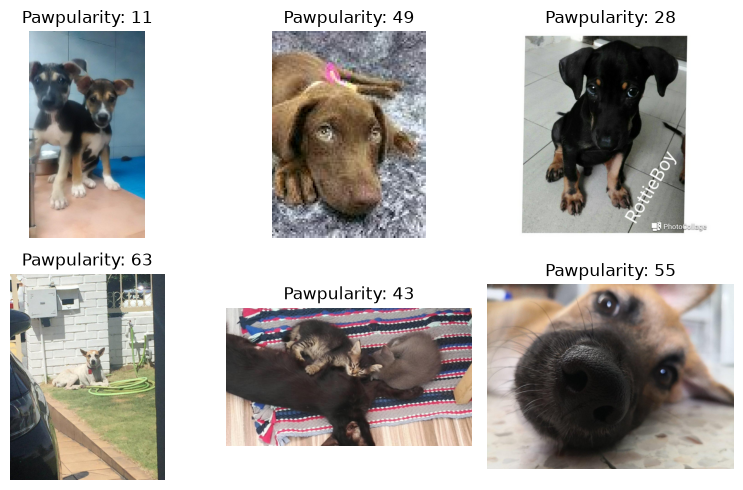

In [5]:
# A few training photos and their Pawpularity scores.
fig, axes = plt.subplots(2, 3, figsize=(8, 5))

for ax, row in zip(axes.flat, train.sample(6, random_state=SEED).itertuples()):
    ax.imshow(Image.open(photos.open(f"train/{row.Id}.jpg")))
    ax.set_title(f"Pawpularity: {row.Pawpularity}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2. Pretrained Model Encoding

Frozen ViT: image → 768 features.

In [6]:
model_id = "google/vit-base-patch16-224-in21k"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load the image processor and pretrained encoder.
processor = AutoImageProcessor.from_pretrained(model_id)
vit = ViTModel.from_pretrained(model_id).to(device)
vit.eval()

print(f"Device: {device} | Features per photo: {vit.config.hidden_size}")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Device: cuda | Features per photo: 768


In [10]:
def encode(ids, batch_size=32):
    batches = []

    for start in tqdm(range(0, len(ids), batch_size)):
        # Read one batch of RGB images.
        images = []
        for photo_id in ids[start:start + batch_size]:
            with Image.open(photos.open(f"train/{photo_id}.jpg")) as image:
                images.append(image.convert("RGB"))

        # Resize and prepare the batch for ViT.
        inputs = processor(images=images, return_tensors="pt").to(device)

        with torch.no_grad():
            # The CLS token gives one feature vector per image.
            features = vit(**inputs).last_hidden_state[:, 0, :]

        batches.append(features.cpu().numpy())

    return np.vstack(batches)

batch_size = 1024
X_train = encode(train.Id.to_numpy(), batch_size=batch_size)
X_test = encode(test.Id.to_numpy(), batch_size=batch_size)

print(X_train.shape, X_test.shape)

  0%|          | 0/8 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
with h5py.File("pawpularity-vit-embeddings.h5", "w") as file:
    file["X_train"] = X_train
    file["X_test"] = X_test

## 3. Local Cross Validation

Five-fold CV uses training data only. Lower RMSE is better.

With saved embeddings, run Setup and Section 1, then resume here.

In [11]:
# [:] copies the data into NumPy arrays before the file closes.
with h5py.File("pawpularity-vit-embeddings.h5", "r") as file:
    X_train = file["X_train"][:]
    X_test = file["X_test"][:]

X_train.shape, X_test.shape

((7929, 768), (1983, 768))

In [12]:
# Tune a decision tree using the same five folds for every setting.
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

tree_pipeline = make_pipeline(
    DecisionTreeRegressor(random_state=SEED),
)

tree_grid = {
    "decisiontreeregressor__max_depth": [3, 8, None],
    "decisiontreeregressor__min_samples_leaf": [1, 30],
}

tree_search = GridSearchCV(
    tree_pipeline,
    tree_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    return_train_score=True,
)
tree_search.fit(X_train, y_train)

print("Best parameters:", tree_search.best_params_)

Best parameters: {'decisiontreeregressor__max_depth': 3, 'decisiontreeregressor__min_samples_leaf': 30}


In [13]:
# fetch the cross validation result
results = pd.DataFrame(tree_search.cv_results_)

pd.DataFrame({
    "Max depth": results.param_decisiontreeregressor__max_depth.fillna("Unlimited"),
    "Min leaf size": results.param_decisiontreeregressor__min_samples_leaf,
    "Train RMSE": -results.mean_train_score,
    "CV RMSE": -results.mean_test_score,
}).sort_values("CV RMSE").round(2)

,Max depth,Min leaf size,Train RMSE,CV RMSE
1,3,30,19.34,19.90
0,3,1,19.34,19.91
3,8,30,16.83,20.91
5,Unlimited,30,15.91,21.60
2,8,1,15.51,22.38
4,Unlimited,1,-0.00,27.58


In [14]:
# Repeat the same process for a random forest.
forest_pipeline = make_pipeline(
    RandomForestRegressor(
        n_estimators=100,
        max_features="sqrt",
        random_state=SEED,
        n_jobs=2,
    ),
)

forest_grid = {
    "randomforestregressor__max_depth": [5, None],
    "randomforestregressor__min_samples_leaf": [1, 10],
}

forest_search = GridSearchCV(
    forest_pipeline,
    forest_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    return_train_score=True,
)
forest_search.fit(X_train, y_train)

print("Best parameters:", forest_search.best_params_)

Best parameters: {'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_leaf': 10}


In [15]:
results = pd.DataFrame(forest_search.cv_results_)

pd.DataFrame({
    "Max depth": results.param_randomforestregressor__max_depth.fillna("Unlimited"),
    "Min leaf size": results.param_randomforestregressor__min_samples_leaf,
    "Train RMSE": -results.mean_train_score,
    "CV RMSE": -results.mean_test_score,
}).sort_values("CV RMSE").round(2)

,Max depth,Min leaf size,Train RMSE,CV RMSE
3,Unlimited,10,13.53,18.73
2,Unlimited,1,7.04,18.76
1,5,10,18.12,19.13
0,5,1,18.07,19.16


## 4. Paradigm Benchmarking

In [16]:
# Reuse the hyperparameters selected by CV.
tree = tree_search.best_estimator_.named_steps["decisiontreeregressor"]
forest = forest_search.best_estimator_.named_steps["randomforestregressor"]

raw_models = {
    "Decision tree": make_pipeline(
        clone(tree),
    ),
    "Random forest": make_pipeline(
        clone(forest),
    ),
    "K nearest neighbors": make_pipeline(
        KNeighborsRegressor(n_neighbors=25),
    ),
    "Linear regression": make_pipeline(
        LinearRegression(),
    ),
}

In [17]:
# Put StandardScaler inside each pipeline.
scaled_models = {
    "Decision tree": make_pipeline(
        StandardScaler(),
        clone(tree),
    ),
    "Random forest": make_pipeline(
        StandardScaler(),
        clone(forest),
    ),
    "K nearest neighbors": make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=25),
    ),
    "Linear regression": make_pipeline(
        StandardScaler(),
        LinearRegression(),
    ),
}

In [18]:
# Fit on training data; report RMSE on the entire held-out test set.
benchmark = {}

for setting, models in [
    ("Without standardization", raw_models),
    ("With standardization", scaled_models),
]:
    benchmark[setting] = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        benchmark[setting][name] = root_mean_squared_error(y_test, predictions)

benchmark = pd.DataFrame(benchmark)
benchmark.columns.name = "Test RMSE ↓"
benchmark.round(2)

Test RMSE ↓,Without standardization,With standardization
Decision tree,20.09,20.09
Random forest,19.19,19.19
K nearest neighbors,18.92,18.92
Linear regression,19.06,19.06


## 5. Visualize some examples

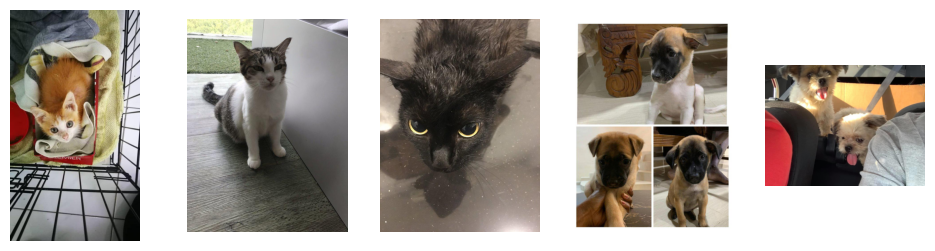

In [19]:
# Select five random test photos.
chosen = np.random.default_rng(SEED).choice(len(test), 5, replace=False)
example_images = [
    Image.open(photos.open(f"train/{photo_id}.jpg")).convert("RGB")
    for photo_id in test.iloc[chosen].Id
]

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax, image in zip(axes, example_images):
    ax.imshow(image)
    ax.axis("off")
plt.show()

In [20]:
# Run the five photos' embeddings through each standardized pipeline.
example_scores = pd.DataFrame({"Ground truth": y_test[chosen]})

for name, model in scaled_models.items():
    example_scores[name] = model.predict(X_test[chosen])

### GPT-6 Astra response

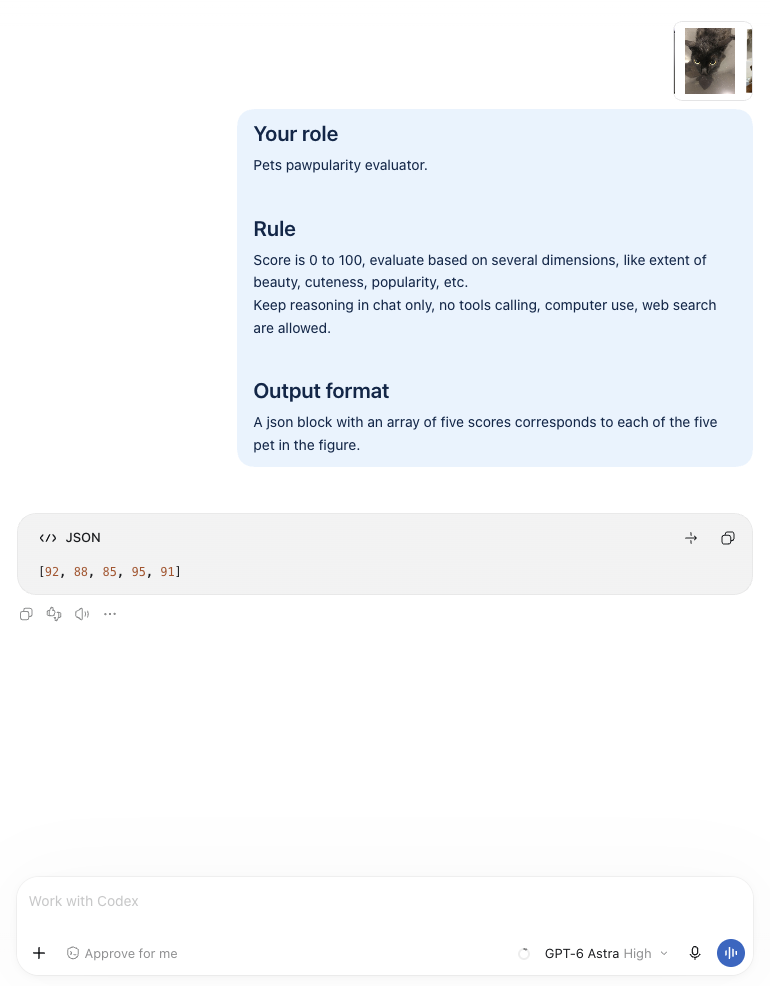

In [21]:
# Add the manually supplied GPT-6 Astra scores in the same photo order.
example_scores["GPT-6 Astra"] = [92, 88, 85, 95, 91]

# Evaluate every model on these same five photos.
example_rmse = {}
for name in example_scores.columns[1:]:
    example_rmse[name] = root_mean_squared_error(
        y_test[chosen],
        example_scores[name],
    )

# Prepare the final table without displaying it yet.
example_scores = example_scores.T
example_scores.columns = [f"Photo {i}" for i in range(1, 6)]
example_scores["5-photo RMSE ↓"] = pd.Series(example_rmse)

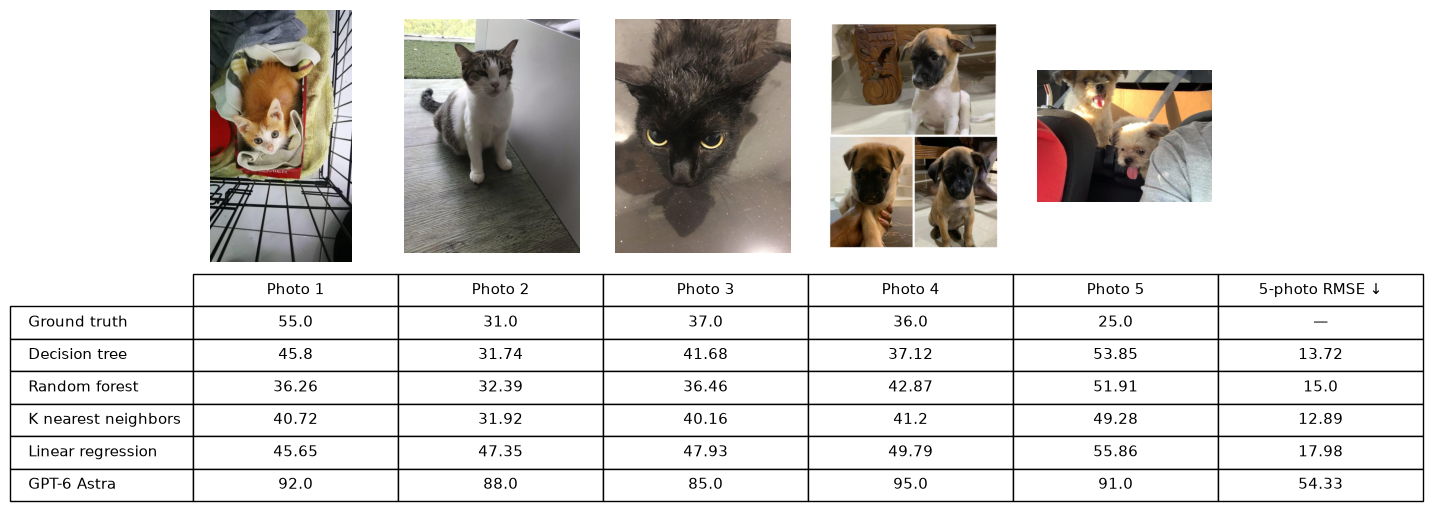

In [22]:
# Visualization of the inference difference
fig = plt.figure(figsize=(15, 5.4))
grid = fig.add_gridspec(2, 6, height_ratios=[2, 1.8])

for column, image in enumerate(example_images):
    ax = fig.add_subplot(grid[0, column])
    ax.imshow(image)
    ax.axis("off")

ax = fig.add_subplot(grid[1, :])
ax.axis("off")
table = ax.table(
    cellText=example_scores.round(2).fillna("—").values,
    rowLabels=example_scores.index,
    colLabels=example_scores.columns,
    cellLoc="center",
    bbox=[0, 0, 1, 1],
)
table.auto_set_font_size(False)
table.set_fontsize(11)

fig.subplots_adjust(
    left=0.17, right=0.99, top=0.97, bottom=0.06, hspace=0.05,
)
plt.show()